# 05 Rooftop solar

Does rooftop solar break the detectors from notebooks 03 and 04?

| Run | Feeder | Season | Customers | Rooftop PV |
|---|---|---|---|---|
| winter (notebooks 01-04) | SimBench `1-LV-semiurb4--0-sw` | 1-28 January | 41 | 1 unit, 6 kWp |
| summer_pv (this notebook) | SimBench `1-LV-semiurb4--2-sw` (the 2034 scenario of the same feeder) | 1-28 June | 58 | 6 units, 172 kWp |

Everything else is unchanged: the same meters, scenarios, detectors and classifier, run again on the summer feeder (`grid.use_run`). Two choices to note:

- SimBench gives all 6 PV units the same profile, so each unit gets a small variation of its own (10 %, for roof direction and shading), like the 30 % already used for customer demand.
- The feeder's 4 home batteries are switched off. They would smooth exactly the signals under test, and how they are controlled is a separate question.

This is the first step: the existing five classes on the solar feeder. Cloud events, inverter trips and attacks hidden in clouds come next.

In [1]:
import sys
from pathlib import Path
import warnings; warnings.filterwarnings("ignore")
import logging; logging.getLogger("pandapower").setLevel(logging.ERROR)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
FIG = ROOT / "figures"
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.precision", 3)
import grid, pipeline, evaluate as ev

## The solar feeder

Transformer power over the same week of each run. Below zero, the feeder exports to the MV grid.

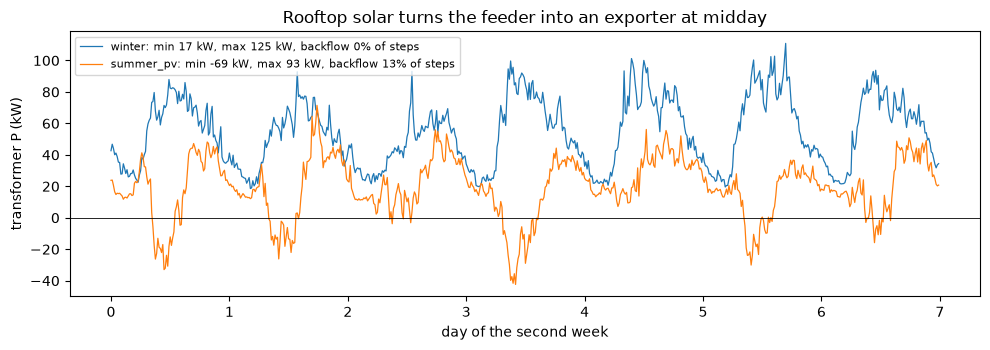

In [2]:
fig, ax = plt.subplots(figsize=(10, 3.6))
for name, colour in [("winter", "tab:blue"), ("summer_pv", "tab:orange")]:
    grid.use_run(name)
    p = -grid.load_results()["res_trafo.p_lv_mw"].iloc[:, 0] * 1e3
    week = p.iloc[7 * 96: 14 * 96].reset_index(drop=True)
    ax.plot(np.arange(len(week)) / 96, week, color=colour, lw=0.9, label=f"{name}: min {p.min():.0f} kW, max {p.max():.0f} kW, backflow {(p < 0).mean():.0%} of steps")
ax.axhline(0, color="k", lw=0.6)
ax.set_xlabel("day of the second week"); ax.set_ylabel("transformer P (kW)")
ax.set_title("Rooftop solar turns the feeder into an exporter at midday"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "pv_backflow.png", dpi=150)

## Run both

The winter run reuses its saved data. The summer run is rebuilt if missing (about 8 minutes the first time).

In [3]:
runs = {name: pipeline.run(name) for name in ["winter", "summer_pv"]}
comparison = pd.DataFrame({name: pipeline.summary(*r) for name, r in runs.items()})
comparison

,winter,summer_pv
WLS: mean J on normal episodes (dof 5),4.960,4.952
WLS: chi-square alarm rate on normal,0.049,0.045
Energy balance: residual std (kW),0.489,0.523
Peer + balance: load_change events detected,0.683,0.300
Peer + balance: meter_fault events detected,0.167,0.067
Peer + balance: attack events detected,0.383,0.217
Peer + balance: consistent attacks detected,0.500,0.167
Peer + balance: false alarms,0.006,0.007
Classifier: load_change events detected,0.929,0.357
Classifier: meter_fault events detected,0.667,0.667


Rows marked *Classifier* are on the test weeks only (days 22-28 of each run); the rest are on all 300 episodes.

## Consistent attacks: the size needed to be seen

winter               summer_pv              
             steps  chi2 balance     steps  chi2 balance
size                                                    
[0.0, 0.25)    433  0.05    0.06       960  0.06    0.01
[0.25, 0.5)    249  0.08    0.23       156  0.12    0.12
[0.5, 1.0)     251  0.29    0.67       118  0.21    0.41
[1.0, 2.0)     221  0.66    0.87        38  0.74    0.53
[2.0, 4.0)     149  0.98    0.96        25  1.00    0.92
[4.0, inf)      77  1.00    1.00        83  1.00    1.00

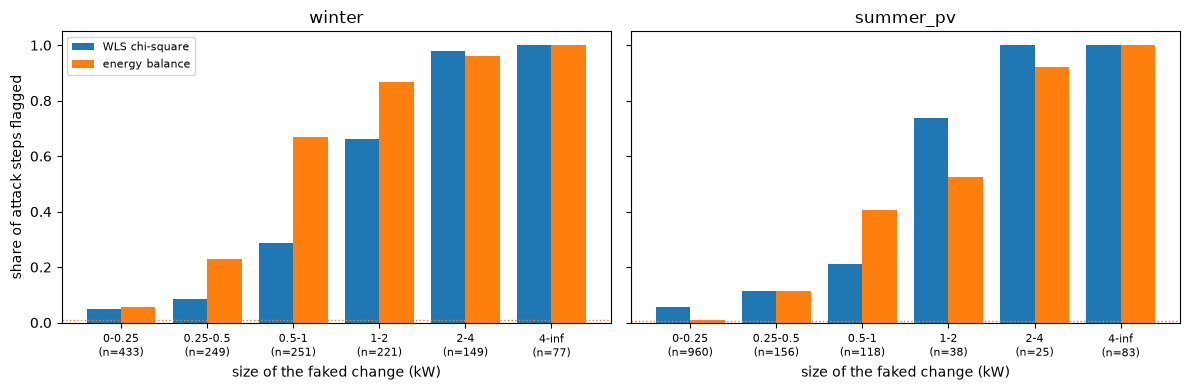

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
tables = {}
for ax, (name, (data, out)) in zip(axs, runs.items()):
    tab = ev.attack_size_table(data, out); ref = ev.reference_rates(data, out); tables[name] = tab
    x = np.arange(len(tab))
    ax.bar(x - 0.2, tab.chi2, 0.4, label="WLS chi-square", color="tab:blue")
    ax.bar(x + 0.2, tab.balance, 0.4, label="energy balance", color="tab:orange")
    ax.axhline(ref.balance, color="tab:orange", ls=":", lw=1)
    ax.set_xticks(x, [f"{iv.left:g}-{iv.right:g}\n(n={n})" for iv, n in zip(tab.index, tab.steps)], fontsize=8)
    ax.set_title(name); ax.set_xlabel("size of the faked change (kW)")
axs[0].set_ylabel("share of attack steps flagged"); axs[0].legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "attack_size_pv.png", dpi=150)
pd.concat(tables, axis=1).round(2)

## Peer check: solar customers vs the rest

Residual std of each meter's peer model on normal history (median over meters). Lower means the peers predict it better, so smaller deviations can be seen.

In [5]:
pd.concat({name: pipeline.peer_quality(*r) for name, r in runs.items()}, axis=0).round(3)

residual std (kW)  residual / mean |P|
          PV customer                                        
winter    False                    0.245                0.699
          True                     0.316                0.214
summer_pv False                    0.181                0.579
          True                     0.330                0.260

## First findings

- **WLS is unaffected.** On normal days the chi-square test behaves exactly as in winter (mean J 4.95 for 5 degrees of freedom, 4.5 % alarms), even with power flowing backwards for 13 % of the time.
- **Detection drops in summer, for two different reasons.**
  1. *Smaller events, not solar.* Summer demand is lower, so the same relative change (a load scaled by 0.2-3x) is smaller in kW: 70 % of consistent-attack steps are below 0.25 kW in summer, against 31 % in winter. That alone cuts the detection rates. It comes from the scenario design, and the comparison should be read by size, not as one number.
  2. *A real solar effect, on the energy balance only.* At the same attack size the balance catches fewer attacks in summer (0.5-1 kW: 41 % vs 67 %; 1-2 kW: 53 % vs 87 %), while the chi-square test does not get worse. The reason is meter noise: it is proportional to the reading, so large PV outputs make the meters noisier at midday. The summer balance mismatch varies twice as much at midday as at night (0.73 vs 0.34 kW), as the meter accuracy predicts (0.65 vs 0.32 kW). WLS weights every reading by its own accuracy, whereas the balance check uses one fixed noise level for the whole day.
- **Peer check.** Solar customers are predicted well *relative to their size* (error 26 % of their mean power, against 58 % for other customers), because neighbours share the same sun. In absolute terms their error is larger (0.33 vs 0.18 kW), so a fixed-size fault is harder to see at a solar customer.
- **The classifier keeps its false alarms in check** (0.7 %) but loses detection like the rules do, for the same two reasons.

**Next step (week 2):** scale the energy-balance check by the expected meter noise at each step, compare attacks by size between the two runs, and add the three solar-specific cases (passing cloud, inverter trip, attack hidden in a cloud).